## Homework Reflection: Weeks 5 - 8 Code Compilation
### Victor Vasquez Gil
Faculty of Computing and Data Science, Boston University
DX702 Experimental Design and Causality

The Markdown cells include my explanations and the same diagrams as the Word reflection. I included code for the simulation, regression, and Week 8 quiz questions.

I use NumPy and pandas for the simulated data, statsmodels for regression, and scikit-learn and SciPy for the Week 8 quiz. The data loader checks for local CSV files first. If they are not there, it loads the original datasets from the instructor's GitHub repository, which is helpful when I run the notebook in Codespaces.

In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from scipy.spatial.distance import mahalanobis

def read_quiz(stem):
    local_files = sorted(Path.cwd().glob(f'{stem}*.csv'))
    if local_files:
        return pd.read_csv(local_files[0])
    url = f'https://raw.githubusercontent.com/joshua-vonkorff/DX702-mod-6/main/{stem}.csv'
    return pd.read_csv(url)

In [3]:
# Draw the Week 5 causal diagrams with Matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

def draw_dag(nodes, arrows, title, figsize=(10, 4.2)):
    """nodes: {name: (x, y, label)}; arrows: (source, target, +/-)."""
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('white')
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 5)
    ax.axis('off')
    for source, target, sign in arrows:
        x1, y1, _ = nodes[source]
        x2, y2, _ = nodes[target]
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2),
                        arrowstyle='-|>', mutation_scale=17, linewidth=1.7,
                        color='#334155', shrinkA=40, shrinkB=58))
        ax.text((x1+x2)/2, (y1+y2)/2+0.20, sign,
                fontsize=13, fontweight='bold', ha='center', va='center',
                bbox=dict(facecolor='white', edgecolor='none', pad=0.8))
    for x, y, label in nodes.values():
        ax.text(x, y, label, ha='center', va='center', fontsize=10.5,
                bbox=dict(boxstyle='round,pad=0.65', fc='#edf4fb',
                          ec='#50647a', lw=1.5), zorder=5)
    ax.set_title(title, fontsize=12.5, pad=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### Week 5 - Question 1: Negative feedback loop
Higher body temperature makes a person sweat more, and sweating helps lower body temperature. I separated the variables into two points in time instead of drawing arrows back and forth between the same nodes. That shows the negative feedback without creating a cycle in the DAG.

The diagram is displayed in the code cell immediately below.

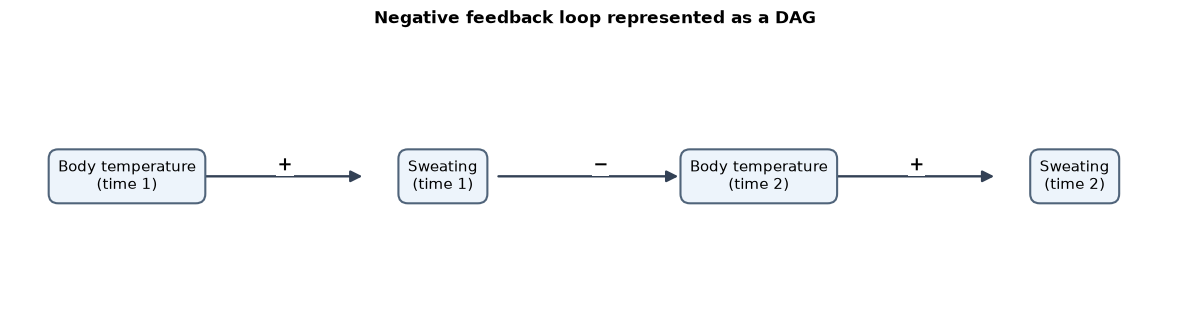

In [4]:
# Week 5, Question 1 - Negative feedback shown across time.
draw_dag({
    't1': (1.0, 2.5, 'Body temperature\n(time 1)'),
    's1': (3.7, 2.5, 'Sweating\n(time 1)'),
    't2': (6.4, 2.5, 'Body temperature\n(time 2)'),
    's2': (9.1, 2.5, 'Sweating\n(time 2)')},
    [('t1', 's1', '+'), ('s1', 't2', '−'), ('t2', 's2', '+')],
    'Negative feedback loop represented as a DAG', figsize=(12, 3.3))

### Week 5 - Question 2: Positive feedback loop
I would use social media engagement as an example. When a post gets more likes, the platform may show it to more people. That added exposure can bring in even more likes, which may lead to another round of exposure. The two reinforce each other over time. I also think it is worth pointing out that more attention does not necessarily mean the post is better or more accurate.

### Week 5 - Question 3: Storms, bears, deer, and flowers
Storms reduce bears and deer but increase flowers. Bears reduce deer, and deer reduce flowers. One backdoor path is Deer ← Storms → Flowers: storms affect both the deer and flower populations. There is also Deer ← Bears ← Storms → Flowers. I would account for storms when estimating the effect of deer on flowers.

I generated 500 made up observations. Storm counts are random, and I added separate noise when generating bears, deer, and flowers, so the simulation does not follow the equations perfectly.

The diagram is displayed in the code cell immediately below.

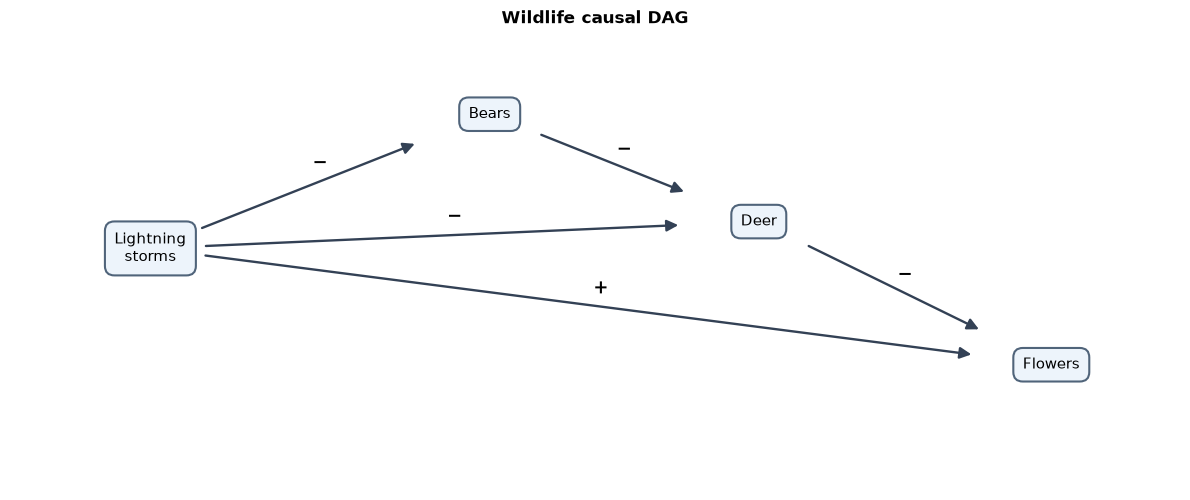

In [6]:
# Week 5, Question 3 - Directed wildlife relationships.
draw_dag({
    'storms': (1.2, 2.7, 'Lightning\nstorms'),
    'bears': (4.1, 4.2, 'Bears'),
    'deer': (6.4, 3.0, 'Deer'),
    'flowers': (8.9, 1.4, 'Flowers')},
    [('storms', 'bears', '−'), ('storms', 'deer', '−'),
     ('storms', 'flowers', '+'), ('bears', 'deer', '−'),
     ('deer', 'flowers', '−')],
    'Wildlife causal DAG', figsize=(12, 5.1))

In [7]:
# Week 5, Question 3 - Simulated wildlife dataset
rng = np.random.default_rng(2026)
storms = rng.poisson(2, 500)
bears = np.maximum(0, 60 - 7*storms + rng.normal(0, 5, 500))
deer = np.maximum(0, 120 - 9*storms - .35*bears + rng.normal(0, 7, 500))
flowers = np.maximum(0, 180 + 12*storms - .45*deer + rng.normal(0, 9, 500))
wildlife = pd.DataFrame(dict(storms=storms, bears=bears, deer=deer, flowers=flowers))
print(wildlife.head().round(1))

   storms  bears  deer  flowers
0       1   46.9  99.2    150.9
1       2   44.8  84.3    178.3
2       2   47.5  83.6    170.2
3       4   28.3  72.0    202.0
4       4   33.9  78.8    208.3


### Week 5 - Question 4: My own DAG - airport staffing and wait times
I would treat staffing as X and passenger wait time as Y. Passenger demand is a confounder because a busier station may add staff and still have longer lines. Customer satisfaction is a collider because both staffing and wait time can affect it. I would not condition on satisfaction when estimating the effect of staffing on wait time, since that could distort the comparison.

The diagram is displayed in the code cell immediately below.

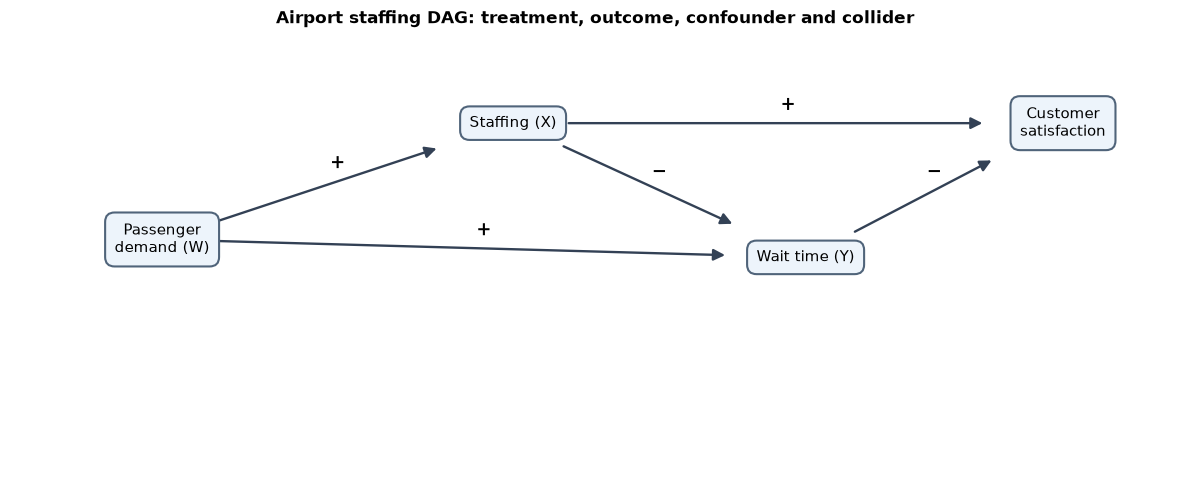

In [9]:
# Week 5, Question 4 — Passenger demand is a confounder; satisfaction is a collider.
draw_dag({
    'demand': (1.3, 2.8, 'Passenger\ndemand (W)'),
    'staff': (4.3, 4.1, 'Staffing (X)'),
    'wait': (6.8, 2.6, 'Wait time (Y)'),
    'satisfaction': (9.0, 4.1, 'Customer\nsatisfaction')},
    [('demand', 'staff', '+'), ('demand', 'wait', '+'),
     ('staff', 'wait', '−'), ('staff', 'satisfaction', '+'),
     ('wait', 'satisfaction', '−')],
    'Airport staffing DAG: treatment, outcome, confounder and collider', figsize=(12, 5.1))

### Week 6 - Question 1: Why the largest estimated effect can be misleading
If I compare enough untreated observations with their estimated counterfactuals, one will probably show an unusually large difference just because of random noise. Taking only the maximum puts the whole estimate on that one observation. Even when I want to know the largest effect, the largest observed difference may be higher than the true one. That is an extreme-value problem, not proof that one unit had such a large treatment effect.

Week 6 - Question 2: Using the 90th percentile as a proxy
I would use the 90th percentile of estimated treatment effects instead of choosing only the largest value. I simulated true effects from 0.5 to 2.0, added noise, and repeated the exercise 600 times. The average observed maximum was 3.852, compared with a true maximum of 2.0, while the average 90th percentile was 2.308. The percentile is less sensitive to one extreme observation, but it measures a different part of the distribution. It is a proxy for a larger effect, not the true maximum, and it will not always be closer.

In [10]:
# Week 6, Question 2 - Maximum versus 90th percentile
rng = np.random.default_rng(702)
true_effect = np.linspace(.5, 2, 1000)
estimates = [true_effect + rng.normal(0, .7, 1000) for _ in range(600)]
print('True maximum:', true_effect.max())
print('Average observed maximum:', round(np.mean([e.max() for e in estimates]), 3))
print('Average 90th percentile:', round(np.mean([np.percentile(e, 90) for e in estimates]), 3))

True maximum: 2.0
Average observed maximum: 3.852
Average 90th percentile: 2.308


### Week 7 - Question 1: Omitted-variable bias
I made W increase both X and Y: X = 0.8W + noise and Y = 2X + 1.5W + noise. The true coefficient on X is 2. Without W in the regression, I got 2.724; after including W, I got 1.987. Leaving W out overestimates X's effect because X also picks up part of W's positive influence on Y. The code compares both models using the same simulated sample.

In [11]:
# Week 7, Question 1 - Leaving out a confounder
rng = np.random.default_rng(702)
w = rng.normal(size=5000)
x = .8*w + rng.normal(size=5000)
y = 2*x + 1.5*w + rng.normal(size=5000)
without_w = sm.OLS(y, sm.add_constant(x)).fit().params[1]
with_w = sm.OLS(y, sm.add_constant(np.column_stack([x, w]))).fit().params[1]
print('True = 2; omitted W =', round(without_w, 3), '; with W =', round(with_w, 3))

True = 2; omitted W = 2.724 ; with W = 1.987


### Week 7 - Question 2: Repeating a significance test
Here I made W and X independent and generated Y = 2X + noise, so W's true coefficient is zero. I fit the regression 1,000 times and recorded the p-value for W each time. The smallest was 0.000241, and 46 tests were below 0.05. That does not mean W actually has an effect. If I keep running tests and only report the most significant one, I can make noise look like a real result.

In [12]:
# Week 7, Question 2 - 1,000 tests under a true null
rng = np.random.default_rng(2026)
pvals = []
for _ in range(1000):
    w, x = rng.normal(size=(2, 300))
    y = 2*x + rng.normal(size=300)
    pvals.append(sm.OLS(y, sm.add_constant(np.column_stack([x, w]))).fit().pvalues[2])
print('Smallest p-value:', round(min(pvals), 6))
print('False positives at 0.05:', sum(p < .05 for p in pvals))

Smallest p-value: 0.000241
False positives at 0.05: 46


### Week 8 - Questions 1 and 2: Propensity scores and IPW
I used logistic regression to estimate each person's probability of treatment from Z. I then compared the treated and untreated outcomes using inverse-probability weights: 1/p for treated observations and 1/(1 − p) for controls. I used normalized weighted means so each group contributes an average. I also printed the first three propensity scores, which the quiz asks for. This method depends on having enough overlap and accounting for the important confounders.

In [ ]:
# Week 8, Questions 1–2  IPW ATE and first three propensity scores
d = read_quiz('homework_8.1')
p = LogisticRegression(max_iter=1000).fit(d[['Z']], d.X).predict_proba(d[['Z']])[:, 1]
t = d.X.to_numpy() == 1
y = d.Y.to_numpy()
ate = np.average(y[t], weights=1/p[t]) - np.average(y[~t], weights=1/(1-p[~t]))
print('IPW ATE:', round(ate, 5))
print('First three propensity scores:', np.round(p[:3], 5))

IPW ATE: 2.27434
First three propensity scores: [0.84011 0.58465 0.71108]


### Week 8 - Questions 3 and 4: Mahalanobis matching and common support
I matched each treated observation to its single nearest untreated observation using Z1 and Z2, with replacement. I used Mahalanobis distance because it accounts for the variables' scales and correlation. To answer Question 4, I found the treated observation whose nearest control was still the farthest away. I reported both that treated point and its nearest control, since the answer choices refer to the control's coordinates. A nearest match is not automatically a good match.

In [14]:
# Week 8, Questions 3–4  Mahalanobis matches with replacement
d = read_quiz('homework_8.2')
t, c = d[d.X == 1], d[d.X == 0]
t_z, c_z = t[['Z1', 'Z2']].to_numpy(), c[['Z1', 'Z2']].to_numpy()
vi = np.linalg.inv(np.cov(d[['Z1', 'Z2']].to_numpy(), rowvar=False))
dist = np.array([[mahalanobis(a, b, vi) for b in c_z] for a in t_z])
nearest = dist.argmin(axis=1)  # same control may be used more than once
ate = np.mean(t.Y.to_numpy() - c.Y.to_numpy()[nearest])
worst = dist[np.arange(len(t)), nearest].argmax()
print('Matched effect:', round(ate, 5))
print('Least-supported treated Z1,Z2:', np.round(t_z[worst], 3))
print('Its nearest control Z1,Z2:', np.round(c_z[nearest[worst]], 3))
print('Nearest-match distance:', round(dist[worst, nearest[worst]], 3))

Matched effect: 3.43768
Least-supported treated Z1,Z2: [2.696 0.538]
Its nearest control Z1,Z2: [ 1.52  -1.282]
Nearest-match distance: 1.383


### Week 8 - Challenges and what I learned

One challenge I ran into was making sure I was using the correct weights for each group and identifying which treated observation had the weakest match. I also learned that the nearest control is not necessarily a good comparison. Even when the calculations work, I still need to consider whether the observations are comparable before interpreting the result as causal.